In [1]:
from anemone.forwards import Forward
from anemone.inversion import BaseInversion, Resistivity
from anemone.system import Loop, Receiver
import torch

import matplotlib.pyplot as plt
import numpy as np

In [2]:
from anemone.forwards import rte

class Forward2(Forward):
    def forward(self):
        if self.H2t is None: self.setup()
        with torch.no_grad():
            cRTE = rte(self.sigma, self.thick, self.omega, self.lamda).squeeze().real
            res = torch.einsum('ik,...k->i...', self.H2t, cRTE)
            if len(res.shape)>1: res = res.mT
            return res


In [3]:
tx = Loop.square(40)
rx = Receiver()
t = torch.logspace(-6, -3, 41)

fwr = Forward2(tx, rx, t, log_scale=True, tolerance=1e-7)
rho_true, thick_true = torch.tensor([20, 80, 40]), torch.tensor([20, 20])
dbdt = fwr(rho_true, thick_true)

res_start = Resistivity.smooth(torch.ones(30)*20., z_bounds=torch.cumsum(torch.logspace(0,1.1,29), dim=0), log_scale=True)

inv = BaseInversion(dbdt, dbdt*0.1, res_start.copy(), fwr.copy())
inv.setup_matrices()

C:\Users\au646858\OneDrive - Aarhus Universitet\Documents\_repositories\anemone\src\anemone\transforms\transforms.py:345: UserWarning: The use of `x.T` on tensors of dimension other than 2 to reverse their shape is deprecated and it will throw an error in a future release. Consider `x.mT` to transpose batches of matrices or `x.permute(*torch.arange(x.ndim - 1, -1, -1))` to reverse the dimensions of a tensor. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4424.)
  return func(lamda/c.sqrt_twopi).T/torch.sqrt(lamda)


In [4]:
fwr = Forward2(tx, rx, t, log_scale=False, tolerance=1e-7)
rho_true, thick_true = torch.tensor([20, 80, 40]), torch.tensor([20, 20])
dbdt = fwr(rho_true, thick_true)

res_start = Resistivity.smooth(torch.ones(30)*20., z_bounds=torch.cumsum(torch.logspace(0,1.1,29), dim=0), log_scale=False)

inv = BaseInversion(dbdt, dbdt*0.1, res_start.copy(), fwr.copy())
inv.setup_matrices()

In [52]:
G0 = inv.jacobian(inv.m)
G1 = fwr(*res_start.mod, jac=True).T
G1 *= res_start.mod[0][None, :]
G1 /= inv._dpred.exp()[:, None]

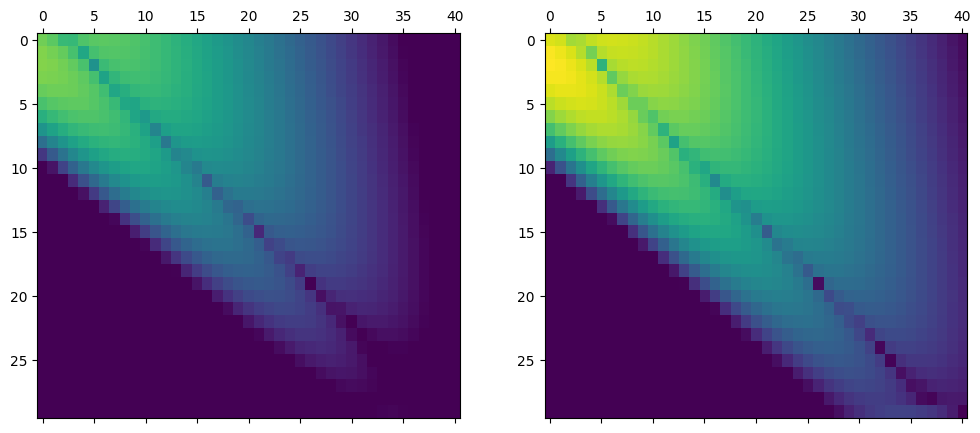

In [53]:
vmax = max(G0.abs().max(), G1.abs().max()).log10()
vmin = -10

fig,axs = plt.subplots(1,2, figsize=(12,5))
axs[0].matshow(G0.abs().log10().T, aspect='auto', vmin=vmin, vmax=vmax)
axs[1].matshow(G1.abs().log10().T, aspect='auto', vmin=vmin, vmax=vmax)

In [54]:
mu0 = 4e-7*torch.pi
def rte_raiche1999(sigma, thickness, omega, wave_length):
    """ raiche 1999 eq 7 and 8
    """
    n_layers=len(sigma)

    lambda2 = wave_length**2
    
    Fj = 0.
    u1 = wave_length*(1 + 1j*omega*mu0*sigma[-1]/lambda2)**0.5

    for i in range(n_layers-2, -1, -1):
        u = wave_length*(1 +  1j*omega*mu0*sigma[i]/lambda2)**0.5
        RTEj = 1j*omega*mu0*(sigma[i] - sigma[i+1])/(u + u1)**2
        exp2uh = torch.exp(-2.*u*thickness[i])
        Fj = exp2uh * (Fj + RTEj) / (1. + Fj * RTEj)
        u1 = u*1.
    RTEj = 1j*omega*mu0*(-sigma[0])/(u + wave_length)**2
    rte = (RTEj+Fj) / (1.+RTEj*Fj)
    return torch.nan_to_num(rte)

In [95]:
def drte_dsigma(sigma, thickness, omega, wave_length):
    """
    Analytic drte/dsigma via Fortran TEM1DRESP.for (Raiche 1999).
    https://github.com/hydrogeophysicsgroup/TEM1D/blob/main/TEM1DRESP.for#L860C1-L942C12

    Index convention (Fortran -> Python):
      W(0..NLAY): W(0)=wave_length (air), W(1..NLAY)=u for conductors+halfspace.
      IPARM=1..NLAY, IPP=IPARM used directly as array index into W/G/R/E.
      sigma[0..NLAY-1] = Fortran SIGS(1..NLAY), SIGS(0)=0 (air).
    Layer axis is 0.
    """
    NLAY = len(sigma)

    # --- Build extended W(0..NLAY): prepend air wavenumber W(0)=wave_length ---
    u_cond = (wave_length**2 + 1j*omega*mu0*sigma)**0.5         # (NLAY, ...)
    u = torch.cat([wave_length.expand_as(u_cond[:1]), u_cond], dim=0)  # (NLAY+1, ...)

    G = torch.zeros_like(u)
    R = torch.zeros_like(u)
    E = torch.zeros_like(u)

    # --- Forward pass: vectorise R and E, keep G sequential (Möbius chain) ---
    H_fwd = u[:-1] + u[1:]                                             # (NLAY, ...)
    dsigs = torch.cat([-sigma[:1], sigma[:-1] - sigma[1:]], dim=0)     # SIGS(i)-SIGS(i+1)
    R[1:] = mu0*1j*omega * dsigs / H_fwd**2

    thks = torch.cat([torch.zeros_like(thickness[:1]), thickness], dim=0)  # (NLAY, ...)
    E[:-1] = torch.exp(-2.*u[:-1]*thks)

    for i in range(NLAY - 1, -1, -1):
        G[i] = E[i] * (G[i+1] + R[i+1]) / (1. + G[i+1] * R[i+1])

    # --- Vectorised derivative computation ---
    #
    # For each IPP in 1..NLAY-1 the sequential loops reduce to:
    #
    #   drte_du[IPP] = DG_IPP[IPP-1] * CP[IPP] + B[IPP-1] * CP[IPP-1]
    #
    # where:
    #   P[k]    = propagation factor at layer k  (k = 0..NLAY-2)
    #   CP[k]   = P[0]*...*P[k-1], CP[0]=1      (cumulative product)
    #   DG_IPP  = first (IPP) DG step
    #   B       = second (IPP1) DG step contribution (linear in DG_IPP)
    #
    # All quantities are (NLAY-1, ...) and computed in parallel across layers.

    denom_k  = (1. + G[1:-1]*R[1:-1])**2                          # (NLAY-1, ...)

    # P[k] = E[k]*(1-R[k+1]^2) / (1+G[k+1]*R[k+1])^2
    P  = E[:-2] * (1. - R[1:-1]**2) / denom_k                    # (NLAY-1, ...)
    CP = torch.cat([torch.ones_like(P[:1]),
                    torch.cumprod(P, dim=0)], dim=0)               # (NLAY,   ...)

    # B[k] = DT_neg[k]*(1-G[k+1]^2)*E[k] / (1+G[k+1]*R[k+1])^2
    DT_neg = -2.*u[:-2] / (u[:-2] + u[1:-1])**2                  # (NLAY-1, ...)
    B = DT_neg * (1. - G[1:-1]**2) * E[:-2] / denom_k            # (NLAY-1, ...)

    # DG_IPP[j] for IPP=j+1 in 1..NLAY-1
    H_ipp   = u[1:-1] + u[2:]                                     # (NLAY-1, ...)
    DG_IPP  = (-2.*thks[1:]*G[1:-1]
               + 2.*u[2:]/H_ipp**2 * E[1:-1]*(1. - G[2:]**2)
                                              / (1. + G[2:]*R[2:])**2)

    # Combine: drte_du[IPP] = DG_IPP * CP[IPP] + B * CP[IPP-1]
    drte_du = torch.zeros_like(u)
    drte_du[1:NLAY] = DG_IPP * CP[1:] + B * CP[:-1]

    # Halfspace IPP=NLAY: E[NLAY-1] * DT_neg_half * CP[NLAY-1]
    drte_du[NLAY] = E[-2] * (-2.*u[-2] / (u[-1] + u[-2])**2) * CP[-1]

    return (drte_du[1:] * 0.5*mu0*1j*omega / u_cond).squeeze().T


In [96]:
G1 = fwr(*res_start.mod, jac=True).T

In [107]:
rho,_ = res_start.mod
cRTE_dsigma = drte_dsigma(fwr.sigma, fwr.thick, fwr.omega, fwr.lamda).real.T
G2 = torch.einsum('ik,...k->i...', fwr.H2t, cRTE_dsigma)*torch.pi*4e-7
G2 /= rho**2

In [108]:
%%timeit
G1 = fwr(*res_start.mod, jac=True).T

77.9 ms ± 7.41 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [115]:
%%timeit
cRTE_dsigma = drte_dsigma(fwr.sigma, fwr.thick, fwr.omega, fwr.lamda).real.T
G2 = torch.einsum('ik,...k->i...', fwr.H2t, cRTE_dsigma)*torch.pi*4e-7
G2 /= rho**2

25.6 ms ± 4.47 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [114]:
%%timeit
dbdt = fwr(*res_start.mod)

24.6 ms ± 3.18 ms per loop (mean ± std. dev. of 7 runs, 100 loops each)


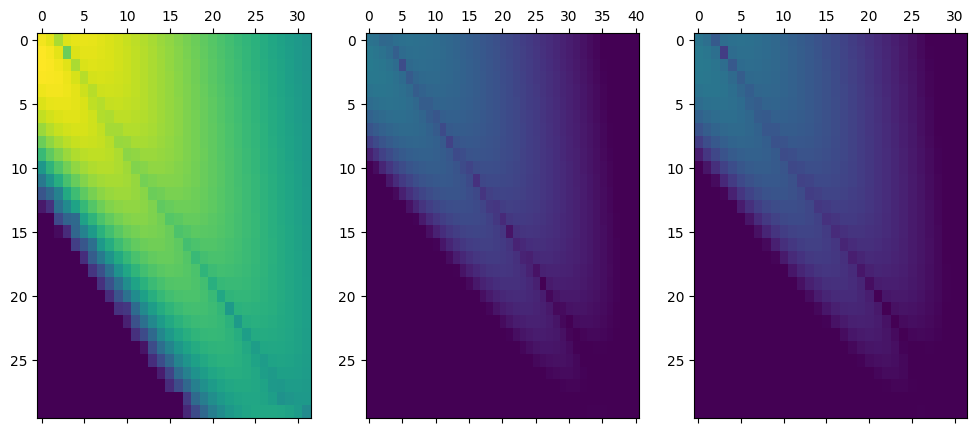

In [110]:
vmax = max(G0.abs().max(), G1.abs().max(), G2.abs().max()).log10()
vmin = -10

fig,axs = plt.subplots(1,3, figsize=(12,5))
axs[0].matshow(G0.abs().log10().T, aspect='auto', vmin=vmin, vmax=vmax)
axs[1].matshow(G1.abs().log10().T, aspect='auto', vmin=vmin, vmax=vmax)
axs[2].matshow(G2.abs().log10().T, aspect='auto', vmin=vmin, vmax=vmax)

ValueError: x and y must have same first dimension, but have shapes (1230,) and (960,)

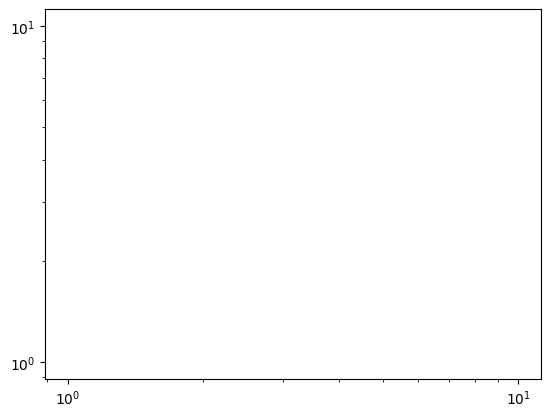

In [111]:
plt.figure()
plt.loglog(G1.abs().flatten(), G0.abs().flatten(), '.', label='G0')
plt.loglog(G1.abs().flatten(), G2.abs().flatten(), '.', label='G2')

<Figure size 640x480 with 0 Axes>

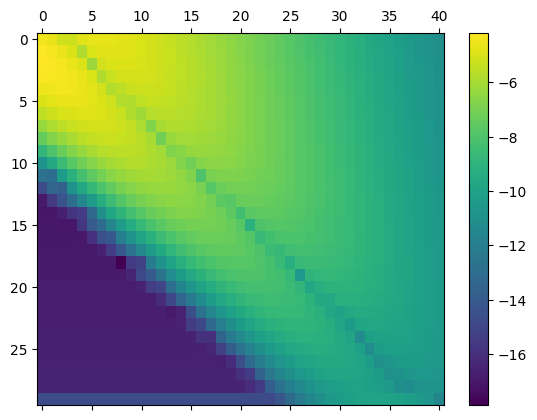

In [104]:
plt.figure()
pcm = plt.matshow(G2.abs().log10().T, aspect='auto')
plt.colorbar(pcm)

In [105]:
t = torch.logspace(-6, -3, 32)

fwr = Forward2(tx, rx, t, log_scale=True, tolerance=None)
res_start = Resistivity.smooth(torch.ones(30)*20., z_bounds=torch.cumsum(torch.logspace(0,1.1,29), dim=0), log_scale=True)
dbdt = fwr(*res_start.mod)

cRTE_dsigma = drte_dsigma(fwr.sigma, fwr.thick, fwr.omega, fwr.lamda).real.T
G0 = torch.einsum('ik,...k->i...', fwr.H2t, cRTE_dsigma)

torch.Size([32, 9730])


C:\Users\au646858\AppData\Local\Temp\ipykernel_27708\3626948010.py:13: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  pcm = axs[i].matshow( 100*np.abs(G-G0) / np.abs(G0), vmin=0, vmax=5)


torch.Size([32, 7901])
torch.Size([32, 6215])
torch.Size([32, 4727])
torch.Size([32, 3388])


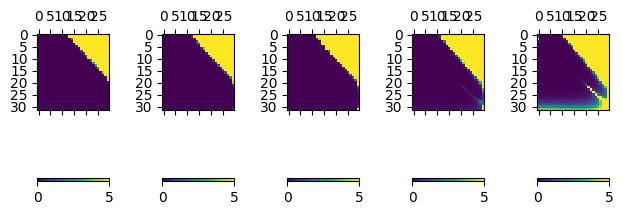

In [106]:
tolerances = [1e-7, 1e-6, 1e-5, 1e-4, 1e-3]
fig,axs = plt.subplots(1, len(tolerances))
for i,tol in enumerate(tolerances):
    fwr = Forward2(tx, rx, t, log_scale=True, tolerance=tol)
    
    res_start = Resistivity.smooth(torch.ones(30)*20., z_bounds=torch.cumsum(torch.logspace(0,1.1,29), dim=0), log_scale=True)
    dbdt = fwr(*res_start.mod)
    print(fwr.H2t.shape)

    cRTE_dsigma = drte_dsigma(fwr.sigma, fwr.thick, fwr.omega, fwr.lamda).real.T
    G = torch.einsum('ik,...k->i...', fwr.H2t, cRTE_dsigma)

    pcm = axs[i].matshow( 100*np.abs(G-G0) / np.abs(G0), vmin=0, vmax=5)
    plt.colorbar(pcm, ax=axs[i], orientation='horizontal')

plt.tight_layout()

In [77]:
print('sigma', fwr.sigma.shape)
print('thick', fwr.thick.shape)
print('omega', fwr.omega.shape)
print('lamda', fwr.lamda.shape)
u_cond = (fwr.lamda**2 + 1j*fwr.omega*mu0*fwr.sigma)**0.5
print('u_cond', u_cond.shape)


sigma torch.Size([30, 1, 1])
thick torch.Size([29, 1, 1])
omega torch.Size([9731])
lamda torch.Size([9731])
u_cond torch.Size([30, 1, 9731])
